In [1]:
# Import pandas, numpy, and matplotlib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# seaborn is a data visualization library built on matplotlib
import seaborn as sns

In [2]:
from pathlib import Path

DATA_DIR = Path('../data')

final_dataset_path = DATA_DIR / 'housing_final.csv'

df = pd.read_csv(final_dataset_path  , dtype = {'county_fips': str})

In [3]:
import statsmodels.formula.api as smf

model_df = df.dropna(
    subset=["average_zhvi", "median_income"]
).copy()

model_1 = smf.ols(
    "average_zhvi ~ median_income",
    data=model_df
).fit()

print(model_1.summary())

                            OLS Regression Results                            
Dep. Variable:           average_zhvi   R-squared:                       0.712
Model:                            OLS   Adj. R-squared:                  0.711
Method:                 Least Squares   F-statistic:                     956.2
Date:                Wed, 28 Oct 2026   Prob (F-statistic):          1.28e-106
Time:                        21:04:19   Log-Likelihood:                -4942.1
No. Observations:                 389   AIC:                             9888.
Df Residuals:                     387   BIC:                             9896.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
Intercept     -1.754e+05   1.71e+04    -10.241

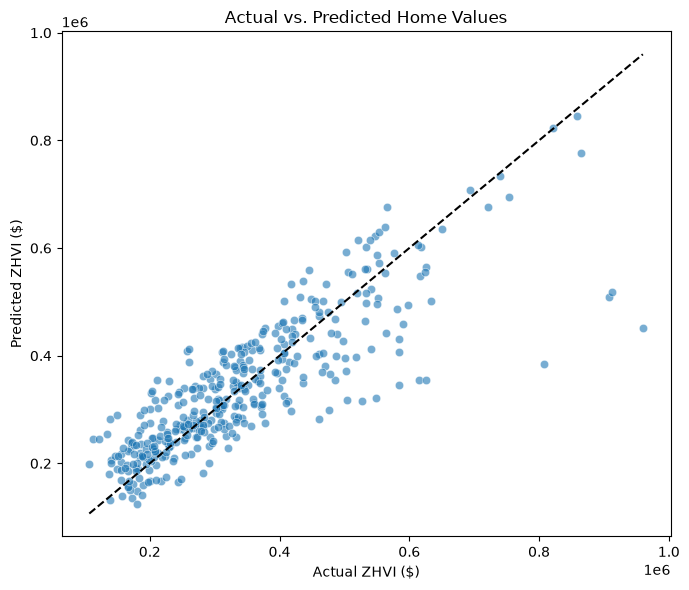

In [4]:
model_df["predicted_zhvi"] = model_1.predict(model_df)

plt.figure(figsize=(7, 6))

sns.scatterplot(
    data=model_df,
    x="average_zhvi",
    y="predicted_zhvi",
    alpha=0.6
)

min_val = min(model_df["average_zhvi"].min(),
              model_df["predicted_zhvi"].min())
max_val = max(model_df["average_zhvi"].max(),
              model_df["predicted_zhvi"].max())

plt.plot([min_val, max_val], [min_val, max_val], "k--")

plt.title("Actual vs. Predicted Home Values")
plt.xlabel("Actual ZHVI ($)")
plt.ylabel("Predicted ZHVI ($)")
plt.tight_layout()
plt.show()